In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 14,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        # embed TrueType fonts in PDF for consistent rendering
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        # use Computer Modern (mathtext + serif fallback)
        "font.family": "serif",
        "font.serif": ["Computer Modern", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        # avoid requiring an external TeX installation by using mathtext
        "text.usetex": False,
    }
)

In [2]:
import os

import jax
import jax.numpy as jnp

os.environ["CUDA_VISIBLE_DEVICES"] = "3"

HORIZON = 50
INITIAL_STATE = jnp.array(
    [0.0, 0.0, 0.0, 1.0]
)  # x, y, theta, v, heading right at 1 m/s

In [3]:
from hcnn.system_dynamics import SystemDynamicsBike

sys_dynamics = SystemDynamicsBike.factory(
    wheelbase=1.0, max_steering=0.6, dt=0.4
)  # 100 * 0.2s * 1m/s -> 20m

In [4]:
from flax import struct

from hcnn.system_constraints import SystemConstraintsBase


@struct.dataclass
class SystemConstraintsSlalom(SystemConstraintsBase):
    state_dim: int
    action_dim: int
    constraint_dim: int
    lower_bound: jax.Array
    upper_bound: jax.Array
    center1: jax.Array
    radius1: float
    center2: jax.Array
    radius2: float
    center3: jax.Array
    radius3: float

    @classmethod
    def factory(cls):
        return cls(
            state_dim=4,
            action_dim=2,
            constraint_dim=3,
            lower_bound=jnp.array([1.0, 1.0, 1.0, -0.6]),
            upper_bound=jnp.array([jnp.inf, jnp.inf, jnp.inf, +0.6]),
            center1=jnp.array([05.0, -0.2]),
            radius1=1.0,
            center2=jnp.array([10.0, +0.2]),
            radius2=1.0,
            center3=jnp.array([15.0, -0.2]),
            radius3=1.0,
        )

    def __call__(self, state: jax.Array, action: jax.Array) -> jax.Array:
        state_xy = state[..., 0:2]
        # keep steering as a trailing dimension so concatenation shapes match
        steering_angle = action[..., 1:2]

        diff1 = state_xy - self.center1
        val1 = jnp.sum(diff1 * diff1, axis=-1, keepdims=True) - (
            self.radius1 * self.radius1
        )

        diff2 = state_xy - self.center2
        val2 = jnp.sum(diff2 * diff2, axis=-1, keepdims=True) - (
            self.radius2 * self.radius2
        )

        diff3 = state_xy - self.center3
        val3 = jnp.sum(diff3 * diff3, axis=-1, keepdims=True) - (
            self.radius3 * self.radius3
        )

        return jnp.concatenate([val1, val2, val3, steering_angle], axis=-1)


sys_constraints = SystemConstraintsSlalom.factory()

In [5]:
from hcnn.optimization_layer import Rollout


def scan_fn(state, _):
    action = jnp.array([0.0, 0.0])  # no steering, no acceleration
    next_state = sys_dynamics(state, action)
    return next_state, (state, action)


states, actions = jax.lax.scan(scan_fn, INITIAL_STATE, None, length=HORIZON)[1]

raw_rollout = Rollout(states, actions)

In [6]:
raw_rollout.states[-1]

Array([19.59999,  0.     ,  0.     ,  1.     ], dtype=float32)

In [7]:
from hcnn.optimization_layer import ProjectionPhi, ProjectionProblem
from hcnn.solver import SQPParameters

projection_problem = ProjectionProblem.factory(
    sys_dynamics=sys_dynamics,
    sys_constraints=sys_constraints,
    horizon=HORIZON,
)
phi = ProjectionPhi(
    states_ref=raw_rollout.states,
    actions_ref=raw_rollout.actions,
    initial_state=INITIAL_STATE,
)
sqp_problem = projection_problem.replace(phi=phi)
sqp_parameters = SQPParameters(
    alpha=1.6,
    sigma=0.1,
    rho=0.1,
    rho_equality_mult=1e3,
    tol_prim=1e-4,
    tol_dual=1e-4,
    epsilon=1e-12,
    max_iter_lin=2_000,
    max_iter_nonlin=25,
    ls_c1=1e-4,
    ls_rho=0.5,
    ls_max_iter=10,
    ls_penalty_weight=50,
)

In [8]:
# from hcnn.solver import sqp_solve

# x_star, sqp_info = sqp_solve(sqp_problem, sqp_parameters)
# optvar = projection_problem.x_to_optvar(x_star)
# proj_rollout = Rollout(
#     states=optvar.states,
#     actions=optvar.actions,
# )

In [9]:
# Manual SQP iterations to log residuals
from functools import partial

import jax.numpy as jnp

from hcnn.solver.solver_sqp import SQPVariables, sqp_step

# Initialize SQP variables
variables = SQPVariables.factory(problem=sqp_problem, parameters=sqp_parameters)

# Lists to store residuals
primal_residuals = []
dual_residuals = []

step_jit = jax.jit(
    partial(sqp_step, problem=sqp_problem, parameters=sqp_parameters)
)

for i in range(sqp_parameters.max_iter_nonlin):
    print(f"Iteration {i + 1}")
    variables = step_jit(variables)
    primal_residuals.append(variables.max_primal_residual)
    dual_residuals.append(variables.max_dual_residual)

# Convert lists to JAX arrays for plotting
primal_residuals = jnp.stack(primal_residuals)
dual_residuals = jnp.stack(dual_residuals)

# Extract final solution
x_star_manual = variables.x
optvar = projection_problem.x_to_optvar(x_star_manual)
proj_rollout = Rollout(
    states=optvar.states,
    actions=optvar.actions,
)

Iteration 1
osqp prim 0.8145281076431274, dual 0.15695953369140625, iter 2000, mult 4.0, infeas False
SQP iter 1/25 | beta: 5.000e-01 | lin iters: 2000
Iteration 2
osqp prim 7.05718994140625e-05, dual 0.0001379251480102539, iter 2000, mult 0.25, infeas False
SQP iter 2/25 | beta: 1.000e+00 | lin iters: 2000
Iteration 3
osqp prim 9.071826934814453e-05, dual 0.0004611015319824219, iter 2000, mult 1.0, infeas False
SQP iter 3/25 | beta: 1.000e+00 | lin iters: 2000
Iteration 4
osqp prim 4.162359982728958e-05, dual 8.966028690338135e-05, iter 1660, mult 2.0, infeas False
SQP iter 4/25 | beta: 1.000e+00 | lin iters: 1660
Iteration 5
osqp prim 8.1953767221421e-05, dual 5.733966827392578e-05, iter 1180, mult 2.0, infeas False
SQP iter 5/25 | beta: 1.000e+00 | lin iters: 1180
Iteration 6
osqp prim 7.219135295599699e-05, dual 4.413723945617676e-05, iter 1100, mult 1.0, infeas False
SQP iter 6/25 | beta: 1.000e+00 | lin iters: 1100
Iteration 7
osqp prim 4.9706803110893816e-05, dual 4.769116640090

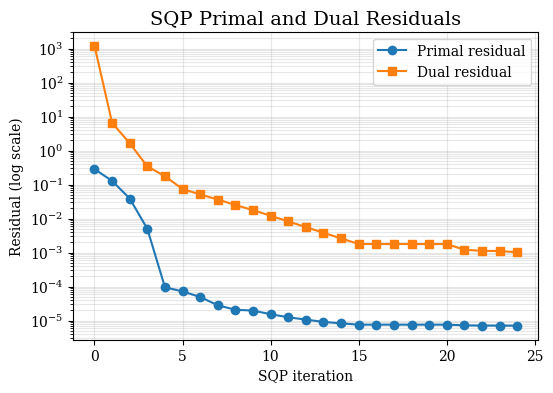

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(primal_residuals, label="Primal residual", marker="o")
ax.plot(dual_residuals, label="Dual residual", marker="s")
ax.set_yscale("log")
ax.set_xlabel("SQP iteration")
ax.set_ylabel("Residual (log scale)")
ax.set_title("SQP Primal and Dual Residuals")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()
fig.savefig("convergence_bike.pdf")

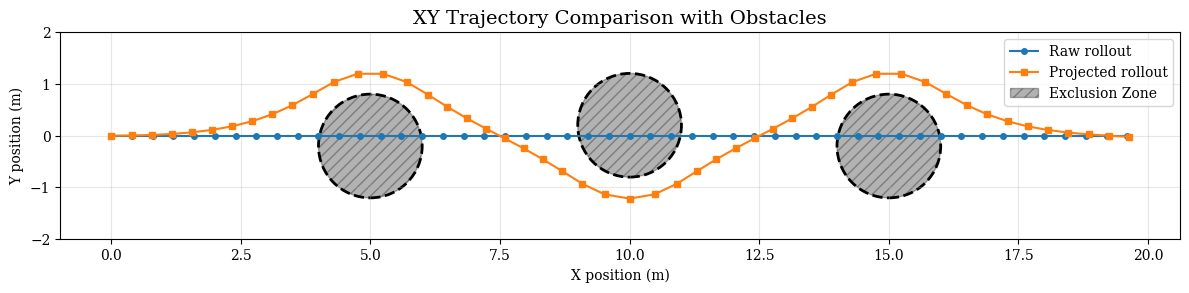

In [11]:
raw_xy = raw_rollout.states[:, :2]
proj_xy = proj_rollout.states[:, :2]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    raw_xy[:, 0],
    raw_xy[:, 1],
    "o-",
    label="Raw rollout",
    markersize=4,
    linewidth=1.5,
)
ax.plot(
    proj_xy[:, 0],
    proj_xy[:, 1],
    "s-",
    label="Projected rollout",
    markersize=4,
    linewidth=1.5,
)

# draw circular obstacles
obstacle_label = False
for center, radius in [
    (sys_constraints.center1, sys_constraints.radius1),
    (sys_constraints.center2, sys_constraints.radius2),
    (sys_constraints.center3, sys_constraints.radius3),
]:
    label = "Exclusion Zone" if not obstacle_label else ""
    circle = plt.Circle(
        tuple(center),
        radius,
        color="k",
        fill=True,
        alpha=0.3,
        label=label,
        hatch="///",
    )
    ax.add_patch(circle)

    # Also add the boundary circle
    circle_boundary = plt.Circle(
        tuple(center),
        radius,
        color="k",
        fill=False,
        linewidth=2,
        linestyle="--",
    )
    ax.add_patch(circle_boundary)
    obstacle_label = True

ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("XY Trajectory Comparison with Obstacles")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_aspect("equal")

# increase y-axis range to [-2, 2]
ax.set_ylim(-2, 2)

plt.tight_layout()
plt.show()
fig.savefig("trajectory_bike.pdf")

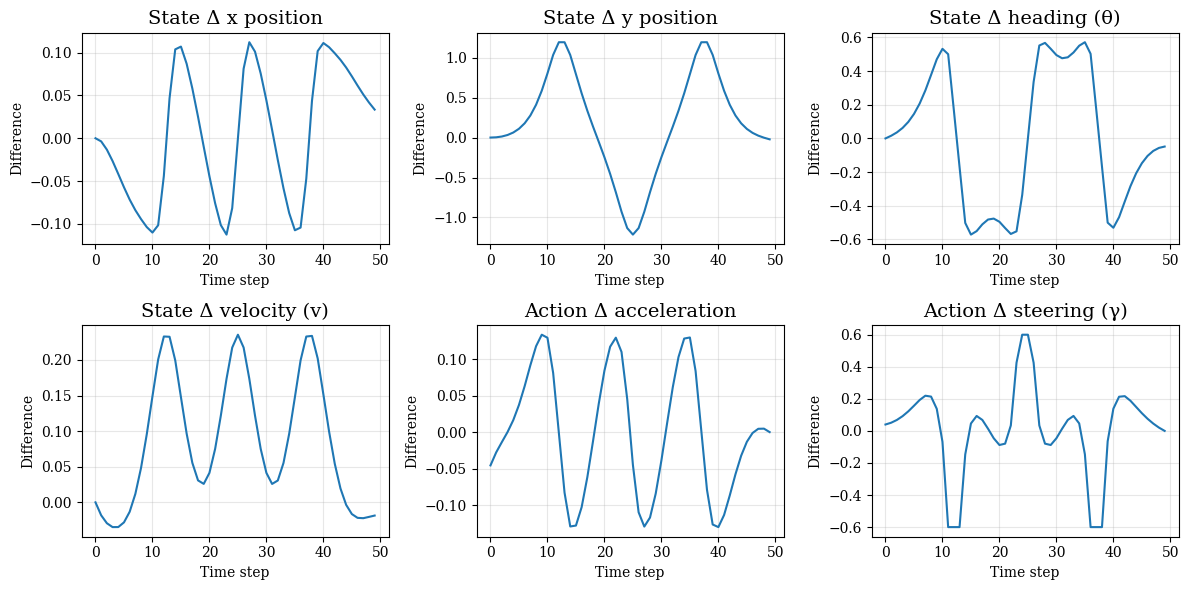

In [12]:
# compute differences between projected and raw rollouts
state_diff = proj_rollout.states - raw_rollout.states
action_diff = proj_rollout.actions - raw_rollout.actions

time = jnp.arange(HORIZON)

# prepare subplots: 4 state dims + 2 action dims
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
state_labels = ["x position", "y position", "heading (θ)", "velocity (v)"]
action_labels = ["acceleration", "steering (γ)"]

# plot state differences
for i in range(4):
    ax = axs.flat[i]
    ax.plot(time, state_diff[:, i])
    ax.set_title(f"State Δ {state_labels[i]}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Difference")
    ax.grid(True, alpha=0.3)

# plot action differences
for i in range(2):
    ax = axs.flat[4 + i]
    ax.plot(time, action_diff[:, i])
    ax.set_title(f"Action Δ {action_labels[i]}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Difference")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
fig.savefig("trajectory_diff_bike.pdf")